# 06 — Model Comparison

The final comparison of the four forecasting models on 2025. Every model made the same 359 rolling 7-day forecasts (one per day from 1 Jan to 25 Dec 2025, each using only data up to the day before) and was scored with the same code.

| Model | Notebook | In one line |
|---|---|---|
| Seasonal naive | 03 | "Same day last week": the benchmark |
| SARIMA | 03 | Weekly seasonal ARIMA with holiday inputs, updated with new data daily |
| Prophet | 03 | Weekly + yearly seasonality and holidays, refitted daily |
| LSTM (5-model ensemble) | 04, 05 | Neural network on the last 14 days plus upcoming calendar; average of 5 seeds |

In [1]:
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
sys.path.append("..")
from src.config import *
from src.evaluation import load_predictions, comparison_table, horizon_table

FINAL_MODELS = {
    "seasonal_naive": "Seasonal naive",
    "sarima": "SARIMA",
    "prophet": "Prophet",
    "lstm_tuned": "LSTM (5-model ensemble)",
}
COLOURS = {"Seasonal naive": "tab:grey", "SARIMA": "tab:blue",
           "Prophet": "tab:green", "LSTM (5-model ensemble)": "tab:red"}

daily = pd.read_csv(PROCESSED_DATA, index_col="date", parse_dates=True)
y_train = daily[TARGET][:TRAIN_END]                 # same MASE scale for every model

all_preds = load_predictions()
missing = set(FINAL_MODELS) - set(all_preds["model"])
assert not missing, f"missing prediction files: {missing}"

preds = all_preds[all_preds["model"].isin(FINAL_MODELS)].copy()
preds["model"] = preds["model"].map(FINAL_MODELS)
preds["abs_error"] = (preds["y_true"] - preds["y_pred"]).abs()

# Fairness check: every model must have been scored on exactly the same forecasts
counts = preds.groupby("model").size()
print(counts.to_string())
assert counts.nunique() == 1, "models have different numbers of predictions"
pairs = preds.groupby("model")[["origin", "date"]].apply(
    lambda g: tuple(map(tuple, g.sort_values(["origin", "date"]).values)))
assert pairs.nunique() == 1, "models were scored on different forecast dates"
print("All models scored on identical forecasts: OK")

model
LSTM (5-model ensemble)    2513
Prophet                    2513
SARIMA                     2513
Seasonal naive             2513
All models scored on identical forecasts: OK


In [2]:
table = comparison_table(preds, y_train)
naive_mae = table.loc["Seasonal naive", "MAE"]
best_classical_mae = table.loc[["SARIMA", "Prophet"], "MAE"].min()
table["MAE vs naive (%)"] = (table["MAE"] / naive_mae - 1) * 100
table["MAE vs best classical (%)"] = (table["MAE"] / best_classical_mae - 1) * 100

display(table.round({"MAE": 0, "RMSE": 0, "MAPE": 2, "MASE": 3,
                     "MAE vs naive (%)": 1, "MAE vs best classical (%)": 1}))

,MAE,RMSE,MAPE,MASE,MAE vs naive (%),MAE vs best classical (%)
LSTM (5-model ensemble),1324.0,1681.0,5.08,0.759,-27.3,-11.3
SARIMA,1493.0,1934.0,5.76,0.856,-18.0,0.0
Prophet,1496.0,1874.0,5.77,0.858,-17.9,0.2
Seasonal naive,1822.0,2392.0,6.89,1.045,0.0,22.0


horizon,1,2,3,4,5,6,7
model,,,,,,,
LSTM (5-model ensemble),1074.0,1219.0,1283.0,1365.0,1410.0,1444.0,1472.0
Prophet,1430.0,1456.0,1477.0,1503.0,1520.0,1536.0,1550.0
SARIMA,973.0,1247.0,1376.0,1541.0,1666.0,1784.0,1865.0
Seasonal naive,1844.0,1852.0,1837.0,1823.0,1812.0,1800.0,1786.0


Best model at each horizon:
horizon
1                     SARIMA
2    LSTM (5-model ensemble)
3    LSTM (5-model ensemble)
4    LSTM (5-model ensemble)
5    LSTM (5-model ensemble)
6    LSTM (5-model ensemble)
7    LSTM (5-model ensemble)


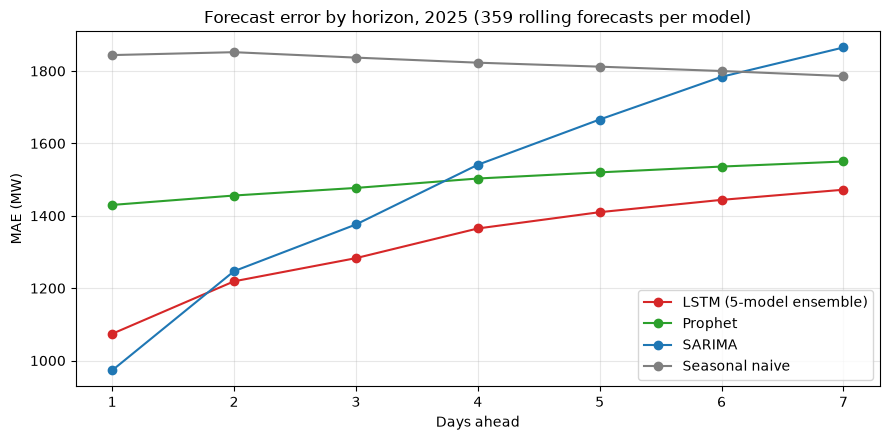

In [3]:
by_h = horizon_table(preds).round(0)
display(by_h)
print("Best model at each horizon:")
print(by_h.idxmin().to_string())

fig, ax = plt.subplots(figsize=(9, 4.5))
for model in by_h.index:
    ax.plot(by_h.columns, by_h.loc[model], marker="o", label=model, color=COLOURS[model])
ax.set_xlabel("Days ahead")
ax.set_ylabel("MAE (MW)")
ax.set_title("Forecast error by horizon, 2025 (359 rolling forecasts per model)")
ax.set_xticks(range(1, HORIZON + 1))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

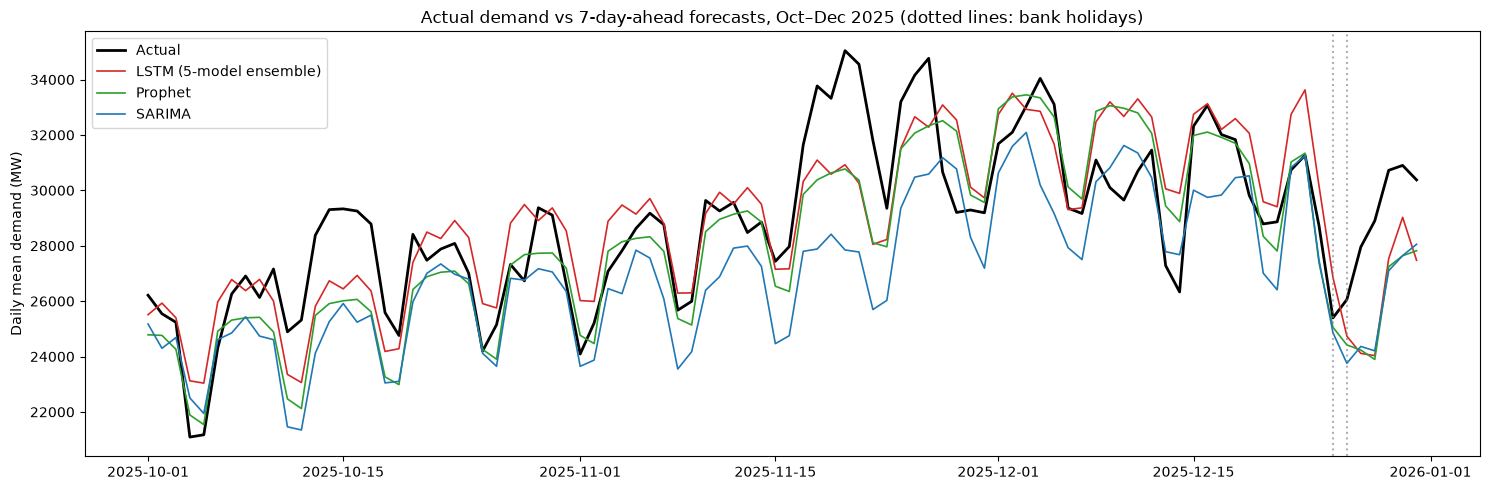

In [4]:
PLOT_HORIZON = 7                                  # try 1 as well: SARIMA looks much better there
PLOT_START, PLOT_END = "2025-10-01", "2025-12-31"

window = preds[(preds["horizon"] == PLOT_HORIZON) & preds["date"].between(PLOT_START, PLOT_END)]
actual = daily.loc[PLOT_START:PLOT_END, TARGET]

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(actual.index, actual, color="black", linewidth=2, label="Actual")
for model, g in window.groupby("model"):
    if model == "Seasonal naive":                 # leave the benchmark out to keep the chart readable
        continue
    g = g.sort_values("date")
    ax.plot(g["date"], g["y_pred"], linewidth=1.2, label=model, color=COLOURS[model])

for d in daily.loc[PLOT_START:PLOT_END].query("is_holiday == 1").index:
    ax.axvline(d, color="grey", linestyle=":", alpha=0.6)

ax.set_title(f"Actual demand vs {PLOT_HORIZON}-day-ahead forecasts, Oct–Dec 2025 (dotted lines: bank holidays)")
ax.set_ylabel("Daily mean demand (MW)")
ax.legend()
plt.tight_layout()
plt.show()

In [5]:
by_month = (preds.assign(month=preds["date"].dt.month)
                 .pivot_table(index="month", columns="model", values="abs_error", aggfunc="mean")
                 .round(0))
by_month = by_month[list(FINAL_MODELS.values())]
display(by_month)
print("Hardest month for each model:")
print(by_month.idxmax().to_string())

model,Seasonal naive,SARIMA,Prophet,LSTM (5-model ensemble)
month,,,,
1,3536.0,2052.0,1753.0,2096.0
2,2224.0,1549.0,2371.0,1872.0
3,2554.0,2046.0,1941.0,1568.0
4,1392.0,1785.0,2265.0,1449.0
5,1241.0,1357.0,1607.0,1070.0
6,1423.0,1118.0,950.0,991.0
7,1224.0,1060.0,912.0,988.0
8,1458.0,1071.0,985.0,1194.0
9,1314.0,1077.0,1053.0,865.0


Hardest month for each model:
model
Seasonal naive             1
SARIMA                     1
Prophet                    2
LSTM (5-model ensemble)    1


## What this shows

**Overall:** the LSTM ensemble is the most accurate model, with an MAE of 1,324 MW. That's 11% lower than SARIMA (1,493) and Prophet (1,496), and 27% lower than seasonal naive. The two classical models are effectively tied: SARIMA has the lower MAE, Prophet the lower RMSE (fewer large misses).

**By horizon (the headline):**
- **Day 1: SARIMA is best** (973 MW vs 1,074 for the LSTM). It uses yesterday's demand most directly.
- **Days 2–7: the LSTM is best**, and its error grows steadily (1,219 → 1,472 MW).
- **SARIMA degrades fastest.** By day 7 (1,865 MW) it's slightly worse than "same day last week" (1,786 MW).
- **Prophet is the flattest** (1,430 → 1,550 MW): weak at day 1, but second-best by day 7.

**Why:** SARIMA knows only the weekly cycle, so a week ahead it can't anticipate seasonal change. The overlay plot shows it consistently under-forecasting as winter demand rises. Prophet knows the yearly cycle but makes little use of recent days. The LSTM combines both: recent history, position in the year (day-of-year features) and upcoming holidays.

**Where all models struggle:**
- **Winter.** Errors roughly double from summer (about 900–1,200 MW per month) to winter (1,300–2,400 MW). January is the hardest month for three of the four models.
- **Short-lived surges.** In late November 2025, demand rose to 34,000–35,000 MW for about two weeks, and every model under-forecast it by a similar margin. When all models miss together, the cause is information none of them has. A cold spell is the likely explanation, which temperature data would confirm.
- **The post-Christmas rebound.** All models predicted the Christmas dip, but kept forecasting holiday-level demand for 29–31 December, when demand had already recovered to about 31,000 MW.

**No model wins everywhere.** The LSTM is best in 5 months, Prophet in 5, SARIMA in 1, and seasonal naive in April. The LSTM wins overall by avoiding large failures rather than by being best every month.

**Limitations and next steps:**
- All models use calendar information only. The winter pattern and the November miss point to **temperature** as the most valuable missing input.
- Results are for one test year (2025), which the EDA showed was the most regular in the data. Errors in noisier years would probably be higher.
- SARIMA's day-1 strength and the LSTM's days 2–7 strength suggest a combined forecast could beat both.